# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:

# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().sum() / len(users) * 100)

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id        0.000
first_name     0.000
last_name      0.000
age            0.000
city          11.725
reg_date       0.000
plan           0.000
churn_date    88.350
dtype: float64


In [11]:
# cantidad de nulos para usage
print(usage.isna().sum())
usage.isna().sum() / len(usage) * 100

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64


id           0.000
user_id      0.000
type         0.000
date         0.125
duration    55.190
length      44.740
dtype: float64

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y qué acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).

* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?

**Diagnóstico del analista**
**users.city:** 469 nulos (11,73 %); investigar los faltantes y el marcador ? antes de decidir si imputar o mantenerlos como desconocidos.
**users.reg_date:** Sin nulos; convertir a formato de fecha (datetime).
**users.churn_date:** 3.534 nulos (88,35 %); verificar si representan clientes que no han cancelado el servicio y mantenerlos como nulos si es así.
**usage.date:** 50 nulos (0,13 %); revisar los registros afectados y mantenerlos como nulos o excluirlos de análisis temporales si no se pueden recuperar.
**usage.duration:** 22.076 nulos (55,19 %); comprobar si corresponden a mensajes y mantenerlos como nulos si no aplica la duración.
**usage.length:** 17.896 nulos (44,74 %); comprobar si corresponden a llamadas y mantenerlos como nulos si no aplica la longitud.


### 2.2 Detección de valores inválidos y sentinels


🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.

El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.


In [12]:
# explorar columnas numéricas de users
users.select_dtypes(include='number').describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id`contiene 4.000 identificadores únicos de usuarios. Aunque sus valores son numéricos, representan identificadores y no cantidades medibles. Por lo tanto, la media y la mediana no aportan información estadística relevante para el análisis.
- La columna `age` contiene 4.000 registros. Se observa un valor mínimo de -999, que parece ser un sentinel utilizado para representar edades inválidas o datos faltantes. Este valor distorsiona las estadísticas descriptivas, especialmente la media. Es necesario identificar y tratar estos valores antes de recalcular las estadísticas.

In [13]:
# explorar columnas numéricas de usage
usage.select_dtypes(include='number').describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


**-Las columnas id y user_id** contienen 40.000 registros. Son identificadores, no variables útiles para el análisis estadístico; user_id permite relacionar los eventos con users.
La columna duration tiene 17.924 valores no nulos, una media de 5,20 y una mediana de 3,50. El 75 % de los valores es igual o inferior a 6,99 y el máximo es 120.
**-La columna length** tiene 22.104 valores no nulos, una media de 52,13 y una mediana de 50. El 75 % de los valores es igual o inferior a 64 y el máximo es 1.490.
**Hipótesis:** los valores máximos de duration y length podrían representar comportamientos poco habituales, aunque no necesariamente sean inválidos.
**Propuesta de investigación:** utilizar boxplots para identificar y analizar los valores extremos antes de decidir si requieren algún tratamiento. Ambas columnas presentan valores faltantes, cuyo tratamiento deberá revisarse posteriormente.

In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
users.isin(['?', 999, -999]).sum()

user_id        0
first_name     0
last_name      0
age           55
city          96
reg_date       0
plan           0
churn_date     0
dtype: int64

In [15]:
users[users['age'].isin(['?', 999, -999])]['age'].value_counts()

-999    55
Name: age, dtype: int64

In [16]:
users['city'].value_counts(dropna=False)

Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

In [17]:
users.duplicated().sum()

0

- La columna `city` tiene 3.531 valores no nulos de 4.000 registros; por tanto, hay 469 valores faltantes.
- La columna `plan` tiene 4.000 valores no nulos; no presenta valores faltantes.
- Ambas columnas son de tipo object, adecuado para almacenar texto.

In [18]:
# explorar columna categórica de usage
columnas_usage = ['type'] 
usage.isin(['?', 999, -999]).sum()

id          1
user_id     0
type        0
date        0
duration    0
length      0
dtype: int64

- La columna `type` Tiene 40.000 registros, todos con valores no nulos.
- Es de tipo object, por lo que almacena categorías como texto.
- No presenta valores faltantes.

In [19]:
usage.duplicated().sum()

0

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?
- **users.age:** Se encontraron 55 valores `-999`. Se propone analizar si están asociados con algún grupo de usuarios antes de decidir si se reemplazan por `NaN`.
- **users.city:** Se encontraron 96 valores `?` y 469 valores `NaN`. Se propone investigar si los `?` se concentran en alguna ciudad o si responden a un problema específico de captura de datos.
- **usage.id:** Se encontró una coincidencia con los valores buscados. Como esta columna es un identificador de registro y no aporta información relevante al análisis, no se considera necesario realizar acciones sobre ella por ahora.
- **users.plan:** No presenta novedades.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [20]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors="coerce", utc=True)

In [21]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors="coerce", utc=True)

In [22]:
print(users.dtypes)
print(usage.dtypes)

user_id                     int64
first_name                 object
last_name                  object
age                         int64
city                       object
reg_date      datetime64[ns, UTC]
plan                       object
churn_date                 object
dtype: object
id                        int64
user_id                   int64
type                     object
date        datetime64[ns, UTC]
duration                float64
length                  float64
dtype: object


In [23]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts().sort_index()

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En `reg_date`, se encontraron fechas correspondientes a los años 2022 (1.314 registros), 2023 (1.316), 2024 (1.330) y 2026 (40). Como los datos están registrados hasta 2024, las 40 fechas de 2026 están fuera del rango esperado y se deben revisar para identificar posibles errores de captura.

In [24]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts().sort_index()

2024.0    39950
Name: date, dtype: int64

In [25]:
usage['date'].sample(10, random_state=42)

32823   2024-05-28 12:40:00.900022500+00:00
16298   2024-03-14 18:00:25.380634515+00:00
28505   2024-05-08 23:43:13.414835370+00:00
6689    2024-01-31 06:26:36.819920498+00:00
26893   2024-05-01 16:39:10.138753468+00:00
36572   2024-06-14 11:49:06.583664590+00:00
12335   2024-02-25 19:36:52.165304132+00:00
29591   2024-05-13 21:39:46.589664740+00:00
18948   2024-03-26 17:48:15.282382059+00:00
31067   2024-05-20 13:57:37.976449410+00:00
Name: date, dtype: datetime64[ns, UTC]

En `date`, se encontraron 39.950 registros correspondientes al año 2024. La revisión aleatoria de 10 filas muestra fechas correctamente formateadas como fecha y hora, con zona horaria UTC.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Revisión de fechas fuera de rango**  
- **users.reg_date:** Se encontraron 40 registros de 2026, fuera del período de análisis. Se propone excluirlos del análisis del proyecto, que se limita a 2024.
- **usage.date:** Los 39.950 registros corresponden a 2024. No se identificaron años fuera del período de análisis.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [26]:
# Reemplazar -999 por la mediana de age
age_mediana = users[users['age'] != -999]['age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [27]:

# Reemplazar ? por NA en city
users['city'] = users['city'].replace("?", pd.NA)
# Verificar cambios
users.isin(['?', 999, -999]).sum()


user_id       0
first_name    0
last_name     0
age           0
city          0
reg_date      0
plan          0
churn_date    0
dtype: int64

In [28]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].dt.year.value_counts().sort_index()

2022.0    1314
2023.0    1316
2024.0    1330
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [29]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration'].isna().groupby(usage['type']).sum()

type
call        0
text    22076
Name: duration, dtype: int64

In [30]:
# Verificación MAR en usage (Missing At Random) para length
usage['length'].isna().groupby(usage['type']).sum()

type
call    17896
text        0
Name: length, dtype: int64

**Diagnóstico de duration y length:**
- duration: presenta 22.076 valores nulos en registros de tipo text y ninguno en call.
- length: presenta 17.896 valores nulos en registros de tipo call y ninguno en text.
**Conclusión:** los nulos dependen de type, lo que indica que son estructurales: duration corresponde a llamadas y length a mensajes de texto. Por tanto, se dejan como nulos, ya que esos campos no aplican al tipo de registro correspondiente.

---

## 🧩Paso 4: Summary statistics de uso por usuario

### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [31]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg(
    cant_mensajes=("is_text", "sum"),
    cant_llamadas=("is_call", "sum"),
    cant_minutos_llamada=("duration", "sum")
).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [32]:
# Renombrar columnas
#Ya fueron nombradas arriba

In [33]:

# Combinar la tabla agregada con el dataset de usuarios
user_profile = pd.merge(
    users,
    usage_agg,
    on='user_id',
    how='left'
)
user_profile.head(5)


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [34]:
# Resumen estadístico de las columnas numéricas
user_profile.describe()


,user_id,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,3999.000000,3999.000000,3999.000000
mean,11999.500000,48.136000,5.524381,4.478120,23.317054
std,1154.844867,17.689919,2.358416,2.144238,18.168095
min,10000.000000,18.000000,0.000000,0.000000,0.000000
25%,10999.750000,33.000000,4.000000,3.000000,11.120000
50%,11999.500000,48.000000,5.000000,4.000000,19.780000
75%,12999.250000,63.000000,7.000000,6.000000,31.415000
max,13999.000000,79.000000,17.000000,15.000000,155.690000


In [35]:
# Distribución porcentual del tipo de plan
print(users['plan'].value_counts())
print(users['plan'].value_counts() / len(users) * 100)

Basico     2595
Premium    1405
Name: plan, dtype: int64
Basico     64.875
Premium    35.125
Name: plan, dtype: float64


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

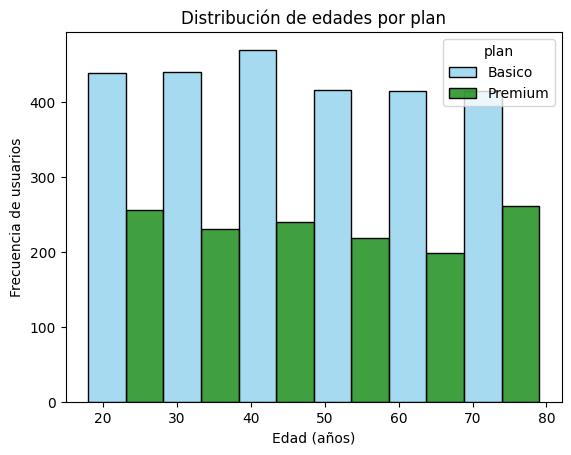

In [36]:
# Histograma para visualizar la edad (age)
sns.histplot(
    data=user_profile,
    x='age',
    hue='plan',
    palette=['skyblue', 'green'],
    multiple='dodge',
    bins=6
)

plt.title('Distribución de edades por plan')
plt.xlabel('Edad (años)')
plt.ylabel('Frecuencia de usuarios')
plt.show()

💡Insights: 

**- Plan básico:** es el plan con más usuarios en todas las edades, con entre 410 y 470 por rango. La distribución es pareja desde los 18 hasta casi los 80 años. Lo único que sobresale un poco es el grupo de alrededor de 40 años, que tiene la barra más alta, con unos 470 usuarios.

**-Plan premium:** tiene casi la mitad de usuarios que el básico, con entre 200 y 260 por rango. También está repartido de forma pareja entre las edades. Hay un poco más de usuarios en los extremos, los más jóvenes y los mayores de 70, y el punto más bajo está alrededor de los 60 años, con unos 200.

**Conclusión:** la edad no parece influir en la elección del plan. En todos los grupos de edad la proporción se mantiene parecida, más o menos dos tercios con básico y un tercio con premium. Las pequeñas diferencias entre grupos no cambian esta tendencia general.

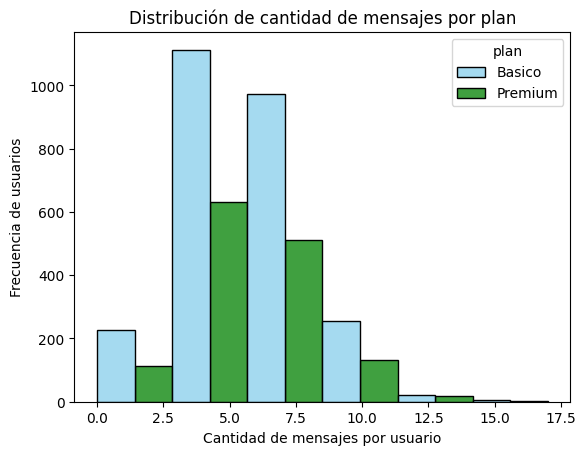

In [37]:
# Histograma para visualizar la cant_mensajes
sns.histplot(
    data=user_profile,
    x='cant_mensajes',
    hue='plan',
    palette=['skyblue', 'green'],
    multiple='dodge',
    bins=6
)

plt.title('Distribución de cantidad de mensajes por plan')
plt.xlabel('Cantidad de mensajes por usuario')
plt.ylabel('Frecuencia de usuarios')
plt.show()

💡Insights: 

**- Plan básico:** la mayoría de usuarios envía entre 3 y 8 mensajes. El grupo más grande está entre 3 y 6 mensajes, con unos 1,100 usuarios, seguido del de 6 a 8, con unos 970. Pocos envían menos de 3 (unos 225) o entre 8 y 11 (unos 255), y casi nadie pasa de 11.

**-Plan premium:** sigue el mismo patrón, pero con casi la mitad de usuarios. También se concentra entre 3 y 8 mensajes, con unos 630 y 510 usuarios en esos dos rangos, y muy pocos pasan de 11.

**-Conclusión:** el tipo de plan no parece influir en la cantidad de mensajes que se envían. Los usuarios del premium no envían más mensajes que los del básico, porque las dos distribuciones tienen la misma forma y la diferencia está solo en el número de usuarios de cada plan. En los dos casos, lo más común es enviar entre 3 y 8 mensajes, y enviar más de 11 es muy raro.

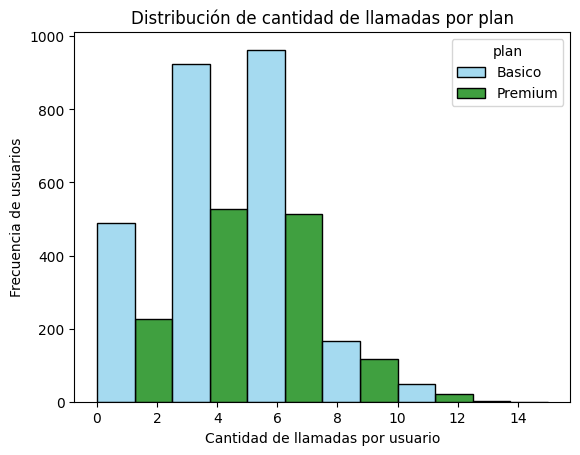

In [38]:
# Histograma para visualizar la cant_llamadas
# Histograma para visualizar la cantidad de llamadas
sns.histplot(
    data=user_profile,
    x='cant_llamadas',
    hue='plan',
    palette=['skyblue', 'green'],
    multiple='dodge',
    bins=6
)

plt.title('Distribución de cantidad de llamadas por plan')
plt.xlabel('Cantidad de llamadas por usuario')
plt.ylabel('Frecuencia de usuarios')
plt.show()

💡Insights: 

**- Plan básico:** la mayoría de usuarios hace entre 2 y 7 llamadas. Los dos grupos más grandes son los de 2 a 5 llamadas (unos 925 usuarios) y de 5 a 7 (unos 960). Hay un grupo importante que hace muy pocas llamadas, de 0 a 2, con unos 490 usuarios. Pocos hacen más de 7 llamadas y casi nadie pasa de 12.

**-Plan premium:** sigue el mismo patrón, con casi la mitad de usuarios. Se concentra entre 2 y 7 llamadas, con unos 525 y 515 usuarios en esos dos rangos. Muy pocos pasan de 10.

**-Conclusión:** el tipo de plan no parece influir mucho en la cantidad de llamadas, ya que las dos distribuciones tienen la misma forma. En ambos casos, lo más común es hacer entre 2 y 7 llamadas. Hay un detalle que vale la pena mencionar: el grupo que hace muy pocas llamadas, de 0 a 2, es proporcionalmente más grande en el básico (unos 490 contra 225 en el premium). Esto sugiere que son más usuarios del plan básico los que casi no llaman. Es una diferencia leve y no cambia la tendencia general.

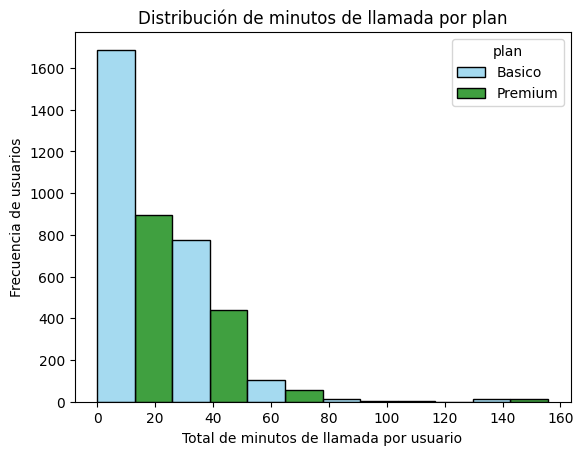

In [39]:
# Histograma para visualizar la cant_minutos_llamada
# Histograma para visualizar la cantidad de minutos de llamada
sns.histplot(
    data=user_profile,
    x='cant_minutos_llamada',
    hue='plan',
    palette=['skyblue', 'green'],
    multiple='dodge',
    bins=6
)

plt.title('Distribución de minutos de llamada por plan')
plt.xlabel('Total de minutos de llamada por usuario')
plt.ylabel('Frecuencia de usuarios')
plt.show()

💡Insights: 

**_Plan básico:** la gran mayoría habla menos de 26 minutos en total (unos 1,690 usuarios). Después la cantidad baja rápido, y muy pocos pasan de 50 minutos.

**-Plan premium:** tiene el mismo patrón, con casi la mitad de usuarios. La mayoría habla menos de 26 minutos y muy pocos pasan de 50.

**-Conclusión:** el plan no parece influir en los minutos de llamada. En los dos planes casi todos hablan poco. Hay unos pocos usuarios atípicos, de los dos planes, que pasan de 130 minutos.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

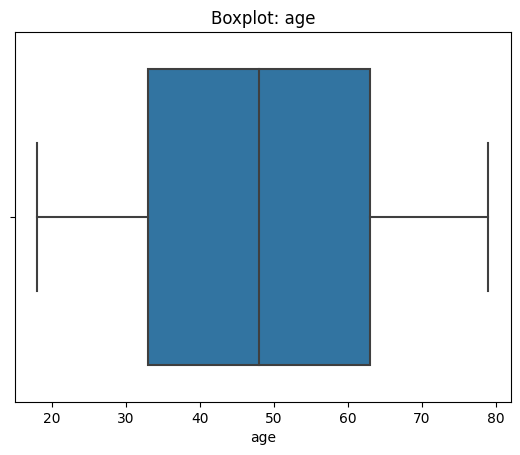

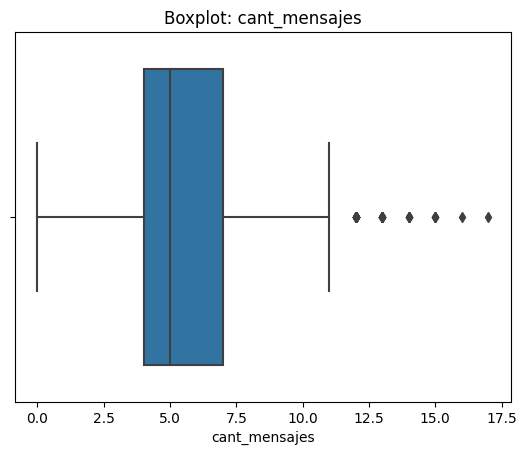

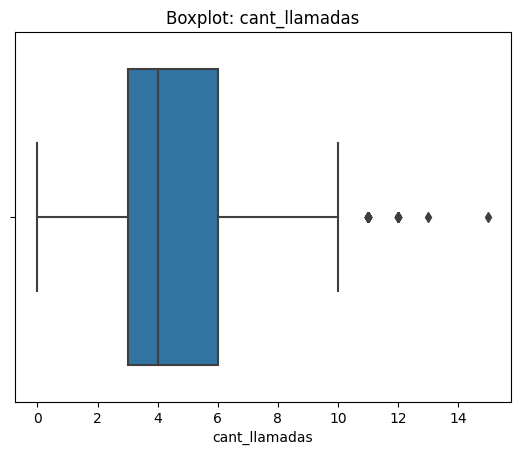

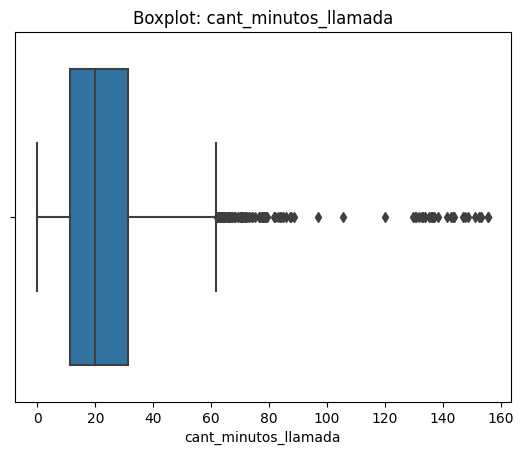

In [40]:

# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data=user_profile, x=col)
    plt.title(f'Boxplot: {col}')
    plt.show()


💡Insights: 

**-Age:** la mitad de los usuarios tiene entre 33 y 63 años, con una mediana de 48. No hay outliers.

**-Cant_mensajes:** la mitad de los usuarios envían entre 4 y 7 mensajes, con una mediana de 5. Hay pocos outliers, de 12 a 17 mensajes. Son usuarios que escriben más que la mayoría, pero no son valores extremos.

**-Cant_llamadas:** la mitad de los usuarios hace entre 3 y 6 llamadas, con una mediana de 4. Hay pocos outliers, de 11 a 15 llamadas, y tampoco son valores extremos.

**-Cant_minutos_llamada:** la mitad de los usuarios habla entre 11 y 31 minutos, con una mediana de 20. Es la variable con más outliers: muchos entre 62 y 90 minutos, y un grupo separado entre 130 y 156 minutos. Vale la pena revisar ese último grupo, porque podría tratarse de usuarios que usan mucho el servicio o de errores en los datos, también para descartar algún tipo de fraude. 

In [41]:
# Calcular límites con el método IQR
columnas_limites = [
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]
for col in columnas_limites:
    q1 = user_profile[col].quantile(0.25)
    q3 = user_profile[col].quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    print(f'Columna: {col}')
    print(f'Q1: {q1}')
    print(f'Q3: {q3}')
    print(f'IQR: {iqr}')
    print(f'Límite inferior: {limite_inferior}')
    print(f'Límite superior: {limite_superior}')
    print('-------------------')

Columna: cant_mensajes
Q1: 4.0
Q3: 7.0
IQR: 3.0
Límite inferior: -0.5
Límite superior: 11.5
-------------------
Columna: cant_llamadas
Q1: 3.0
Q3: 6.0
IQR: 3.0
Límite inferior: -1.5
Límite superior: 10.5
-------------------
Columna: cant_minutos_llamada
Q1: 11.12
Q3: 31.415
IQR: 20.295
Límite inferior: -19.322500000000005
Límite superior: 61.8575
-------------------


In [42]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 

**-cant_mensajes:** Mantener, porque un alto número de mensajes puede reflejar un uso real del servicio.

**-cant_llamadas:** Mantener, porque algunos usuarios pueden realizar más llamadas que otros.

**-cant_minutos_llamada:** Mantener, porque algunos usuarios pueden tener llamadas más largas sin que sean errores.


---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [55]:

user_profile.columns

Index(['user_id', 'first_name', 'last_name', 'age', 'city', 'reg_date', 'plan',
       'churn_date', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada'],
      dtype='object')

In [57]:

# Crear columna grupo_uso
def grupo_uso (row):
    llamadas = row['cant_llamadas']
    mensajes = row['cant_mensajes']

    #Segmentación Bajo Uso <5 y <5
    if llamadas < 5 and mensajes < 5:
            return "Bajo uso"

    #Segmentación Uso medio <10 y <10 
    elif llamadas < 10 and mensajes < 10:
            return "Uso medio"
            
    #segmentación Alto uso - resto de casos 
    else: 
        return "Alto uso"
            
#Aplicar función y ver cambios
user_profile["grupo_uso"] = user_profile.apply(grupo_uso, axis = 1 )
user_profile[["grupo_uso", "cant_llamadas", "cant_mensajes"]].head()


,grupo_uso,cant_llamadas,cant_mensajes
0,Uso medio,3.0,7.0
1,Alto uso,10.0,5.0
2,Uso medio,2.0,5.0
3,Alto uso,3.0,11.0
4,Bajo uso,3.0,4.0


In [59]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [64]:

# Crear columna grupo_edad
def grupo_edad (row):
    age = row['age']

    #Segmentación Joven < 30
    if age < 30:
            return "Joven"
         #Segmentación Adulto < 60
    elif age < 60:
            return "Adulto"
        #segmentación Adulto Mayor
    else: 
        return "Adulto Mayor"

    #Aplicar función y ver cambios
user_profile["grupo_edad"] = user_profile.apply(grupo_edad, axis = 1 )
user_profile[["grupo_edad", "cant_llamadas", "cant_mensajes"]].head()

    

,grupo_edad,cant_llamadas,cant_mensajes
0,Adulto,3.0,7.0
1,Adulto,10.0,5.0
2,Adulto,2.0,5.0
3,Adulto Mayor,3.0,11.0
4,Adulto Mayor,3.0,4.0


In [63]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

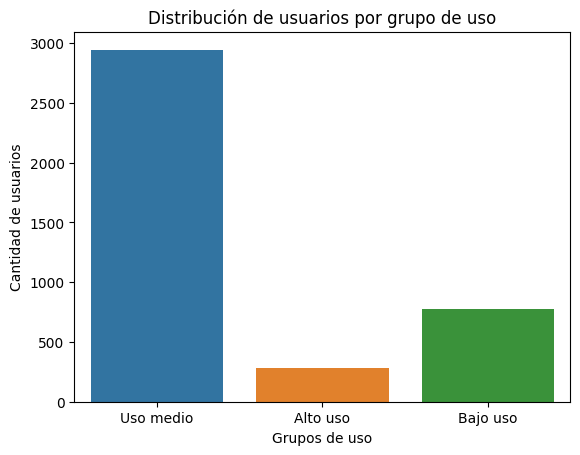

In [66]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso')
plt.title("Distribución de usuarios por grupo de uso")
plt.xlabel("Grupos de uso")
plt.ylabel("Cantidad de usuarios")
plt.show()

In [69]:
user_profile['grupo_uso'].value_counts(normalize=True).mul(100).round(2)

Uso medio    73.58
Bajo uso     19.45
Alto uso      6.98
Name: grupo_uso, dtype: float64

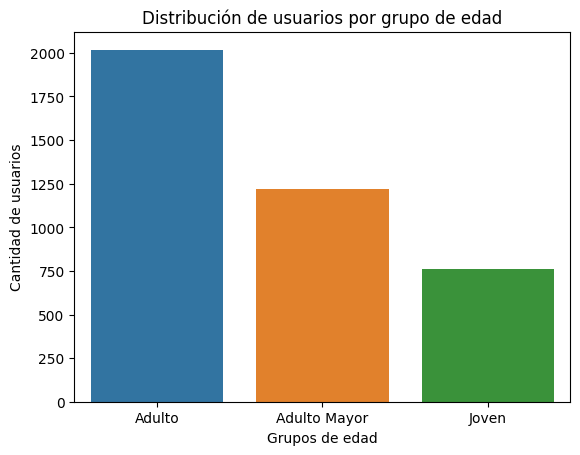

In [67]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad')
plt.title("Distribución de usuarios por grupo de edad")
plt.xlabel("Grupos de edad")
plt.ylabel("Cantidad de usuarios")
plt.show()

In [68]:
user_profile['grupo_edad'].value_counts(normalize=True).mul(100).round(2)

Adulto          50.45
Adulto Mayor    30.55
Joven           19.00
Name: grupo_edad, dtype: float64


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

- **Datos faltantes:** se identificaron 469 valores nulos en `users.city` (11,73 %) y 3.534 en `users.churn_date` (88,35 %), además de valores faltantes en variables de uso. Se consideró el significado de cada campo para distinguir los faltantes esperables de los que podían afectar el análisis.

- **Valores inválidos:** se encontraron 55 registros con `age = -999`, que se reemplazaron por la mediana de edad, y 96 valores `?` en `city`, que se convirtieron en valores nulos.

- **Fechas fuera del período de análisis:** se retiraron los registros con fechas posteriores a 2024, dado que el período de estudio abarcaba hasta ese año.

- **Valores atípicos:** se identificaron mediante diagramas de caja (*boxplots*) y se caparon para limitar la influencia de los valores extremos sin eliminar los registros, conservando así la información de los usuarios para el análisis.


🔍 **Segmentos por Edad**

- **Adultos (30–59 años):** representan el 50,45 % de los usuarios.
- **Adultos mayores (60 años o más):** representan el 30,55 %.
- **Jóvenes (menores de 30 años):** representan el 19,00 %.
- **Distribución de edades:** la mediana es de 48 años y el 50 % de los usuarios tiene entre 33 y 63 años.
- **Valores atípicos:** no se identificaron valores atípicos en la variable `age` mediante el análisis de diagramas de caja (*boxplots*).

**Conclusión:** la base de clientes se concentra en los adultos de 30 a 59 años, seguidos por los adultos mayores. Esta distribución permite reconocer los principales grupos etarios de la base de clientes, aunque no demuestra por sí sola que la edad determine sus patrones de consumo.

📊 **Segmentos por Nivel de Uso**
-El 73,58 % de los clientes presenta un uso medio de llamadas y mensajes, mientras que el 19,45 % registra bajo uso y el 6,98 % alto uso.

➡️ Esto sugiere que el consumo medio constituye el patrón predominante entre los clientes de ConnectaTel, mientras que los segmentos de bajo y alto uso ofrecen oportunidades para profundizar en el comportamiento de los usuarios y evaluar posibles estrategias de fidelización y adecuación de los planes.

💡 **Recomendaciones**

**-Diseñar estrategias diferenciadas por nivel de uso:** explorar acciones de activación para los clientes de bajo uso y evaluar las necesidades de los clientes de alto uso, manteniendo la atención en el segmento predominante de uso medio.

**-Evaluar la adecuación de los planes:** comparar los niveles de uso con los planes contratados para identificar posibles oportunidades de ajuste y determinar si existen diferencias relevantes entre los segmentos.

**-Profundizar en el análisis por edad:** comparar patrones de consumo entre grupos etarios para establecer si existen diferencias que justifiquen estrategias diferenciales. 

**-Fortalecer la calidad de los datos:** establecer controles para detectar valores inválidos, fechas fuera del periodo y datos faltantes que puedan afectar futuros análisis. 

**-Ampliar el análisis del comportamiento de los cllientes:** explorar la relación entre el uso y los servicios, el plan contratado y la permanencia de los usuarios para orientar futuras decisiones comerciales. 


---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`